In [1]:
# Packages and modules
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, Pauli
from qiskit_aer import AerSimulator
import numpy as np
import matplotlib.pyplot as plt
from qiskit_ibm_runtime import  EstimatorV2
from qiskit.quantum_info import SparsePauliOp
from qiskit_ibm_runtime import QiskitRuntimeService

In [2]:
"-------------------Floquet evolution operator construction-------------------"
def create_trotter_circuit(num_qubits, Jz, hz, hx, trotter_steps):

    qc = QuantumCircuit(num_qubits)
    for _ in range(trotter_steps):

        # Longitudinal Z field
        for i in range(num_qubits):
            qc.rz(2 * hz, i)

        # Even bonds: ZZ interactions
        for i in range(0, num_qubits - 1, 2):
            qc.rzz(2 * Jz, i, i + 1)

        # Odd bonds: ZZ interactions
        for i in range(1, num_qubits - 1, 2):
            qc.rzz(2 * Jz, i, i + 1)

        # Transverse X kick
        for i in range(num_qubits):
            qc.rx(2 * hx, i)

    return qc


"-------------------initial State construction-------------------"
# Domail wall
def domain_wall(num_qubits) -> QuantumCircuit:
    init_qc = QuantumCircuit(num_qubits)
    for i in range(num_qubits//2):
        init_qc.x(i)
    return init_qc

# Nèel(CDW) state
def neel(num_qubits) -> QuantumCircuit:
    init_qc = QuantumCircuit(num_qubits)
    for i in range(num_qubits) :
        if i%2 ==0:
            init_qc.x(i)

    return init_qc


"------------------- Operators -------------------"
def imbalance_operator(num_qubits: int) -> SparsePauliOp:
    pauli_list = []
    for i in range(num_qubits):
        p = ['I'] * num_qubits
        p[i] = 'Z'
        coeff = (-1) ** i
        pauli_list.append(("".join(p), coeff/num_qubits))
    return SparsePauliOp.from_list(pauli_list)


def magnetization(num_qubits) -> list:
    mag_ops = [
        SparsePauliOp.from_sparse_list([("Z", [q], 1.0)], num_qubits=num_qubits)
        for q in range(num_qubits)
    ]

    return mag_ops

In [ ]:
"------------------- backend -------------------"
# Simulator Backend
backend = AerSimulator()
estimator = EstimatorV2(mode = backend)

"------------------- Parameters -------------------"
# total number of sites for floquet evolution
num_qubits = 20

# Coefficients for our XXZ Hamiltonian
Jz = 1

# field-strength
hx = 1
hz = 1

# Time Period
T = 1

# maximum number of trotter steps/floquet repetion
max_ntrot = 50

In [4]:
"------------------- Constructing Circuit for Submisson -------------------"

initial_circuit = neel(num_qubits)
operator = imbalance_operator(num_qubits)

imbalance_values = []
floquet_periods = []

for m in range(max_ntrot+1):
    if m == 0:
        full_circuit = initial_circuit
    else: 
        evolution_circuit = create_trotter_circuit(num_qubits, Jz*T, hz*T, hx, m)
        full_circuit = initial_circuit.compose(evolution_circuit)

    job = estimator.run([(full_circuit, operator)])
    pub_result = job.result()[0]
    imbalance_values.append(pub_result.data.evs)
    floquet_periods.append(m)


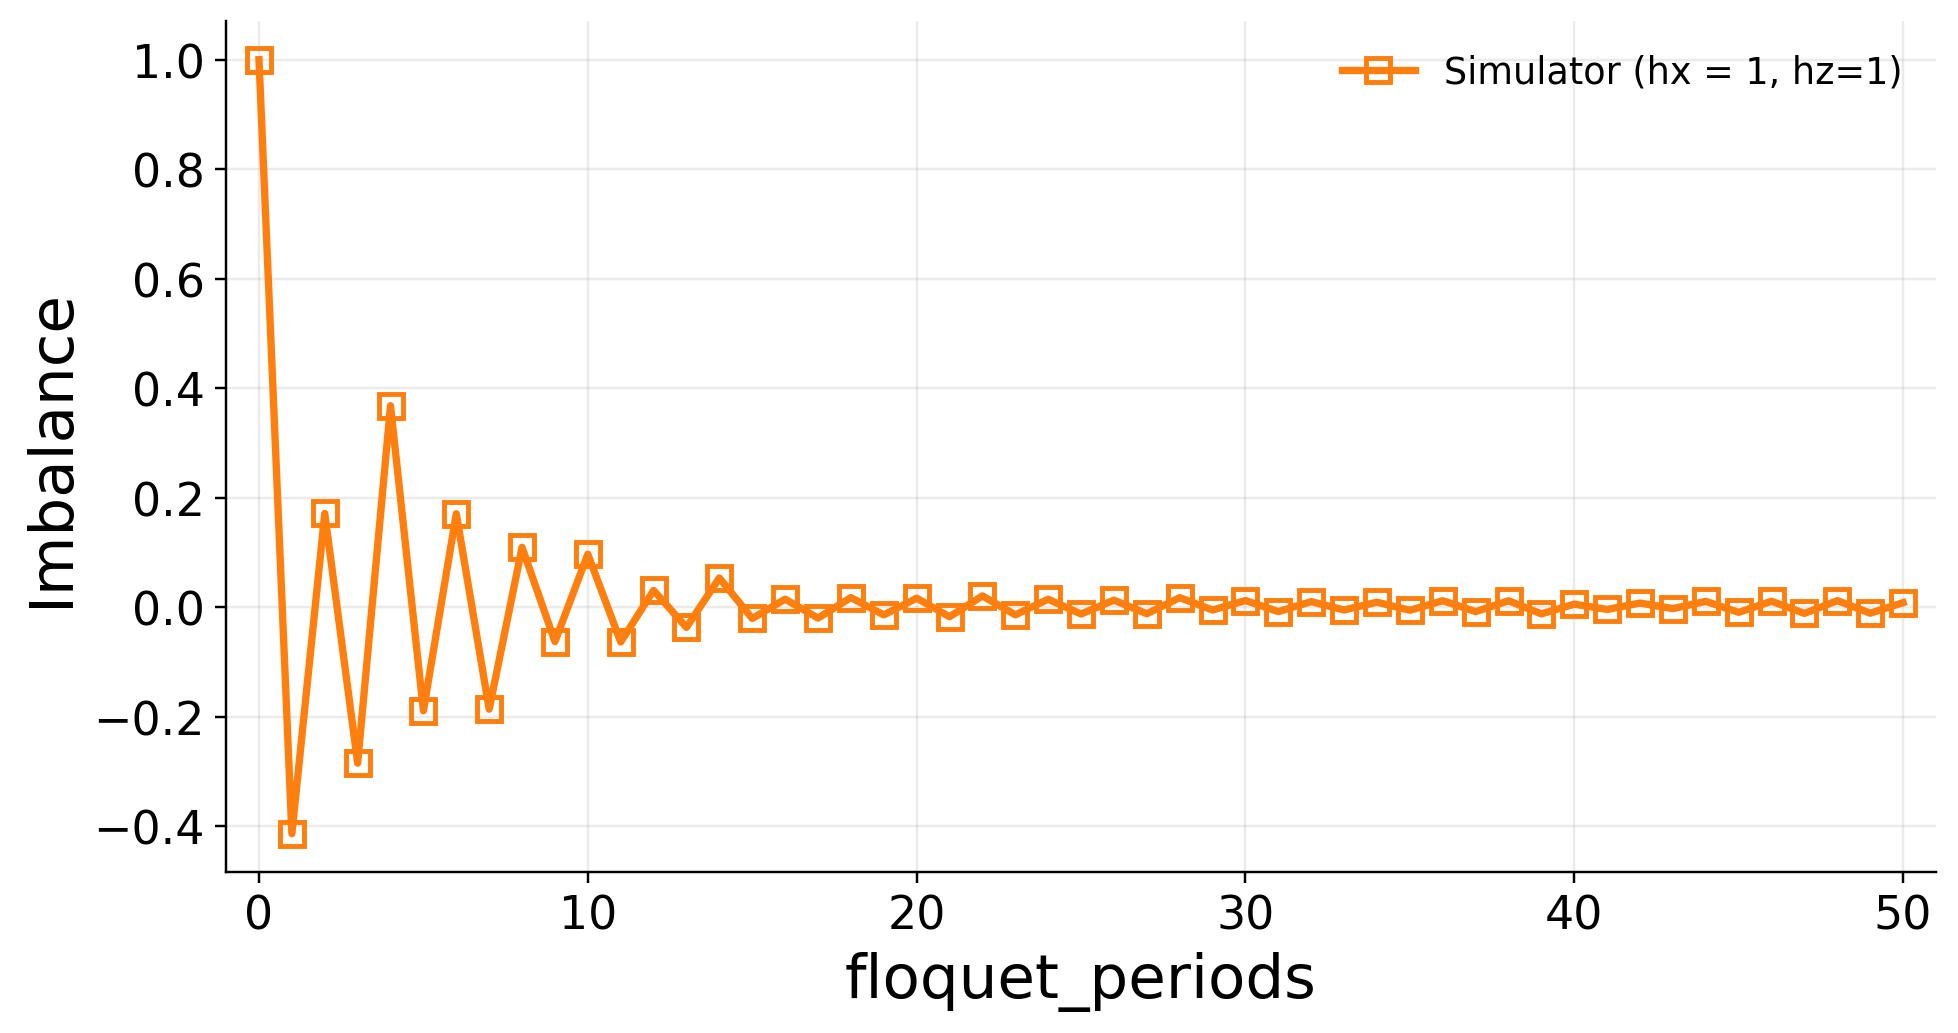

In [5]:
"------------------- Ploting Simulator Results -------------------"
c_sim = "#ff7f0e"  # orange
c_hw  = "#1f77b4"  # blue
c_ed  = "#2ca02c"  # green

fig, ax = plt.subplots(figsize=(9, 4.8), dpi=220)

# Simulator (Trotter S=6, h=6) — solid + hollow squares
ax.plot(floquet_periods, imbalance_values,
        linestyle="-", linewidth=2.4,
        marker="s", markersize=8, markerfacecolor="none", markeredgewidth=1.6,
        color=c_sim, label=f"Simulator (hx = {hx}, hz={hz})")


ax.set_xlabel("floquet_periods", fontsize=20)
ax.set_ylabel("Imbalance", fontsize=20)
ax.tick_params(labelsize=15)
ax.grid(alpha=0.25, linewidth=0.8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.margins(x=0.02)
ax.legend(frameon=False, fontsize=12, loc="upper right")

plt.tight_layout()
plt.show()

In [ ]:
# "------------------- Data from hardware and analysis -------------------"

# service = QiskitRuntimeService()


# job_id = "db7oqdor1c5c738l0nlg"
# job = service.job(job_id)

# print("Job status:", job.status())

# result = job.result()

# imbalance_hardware = np.array([
#     float(np.asarray(pub.data.evs).item())
#     for pub in result
# ])

# imbalance_errors = np.array([
#     float(np.asarray(pub.data.stds).item())
#     for pub in result
# ])



qiskit_runtime_service.__init__:WARNING:2026-10-14 21:06:23,018: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().


Job status: DONE


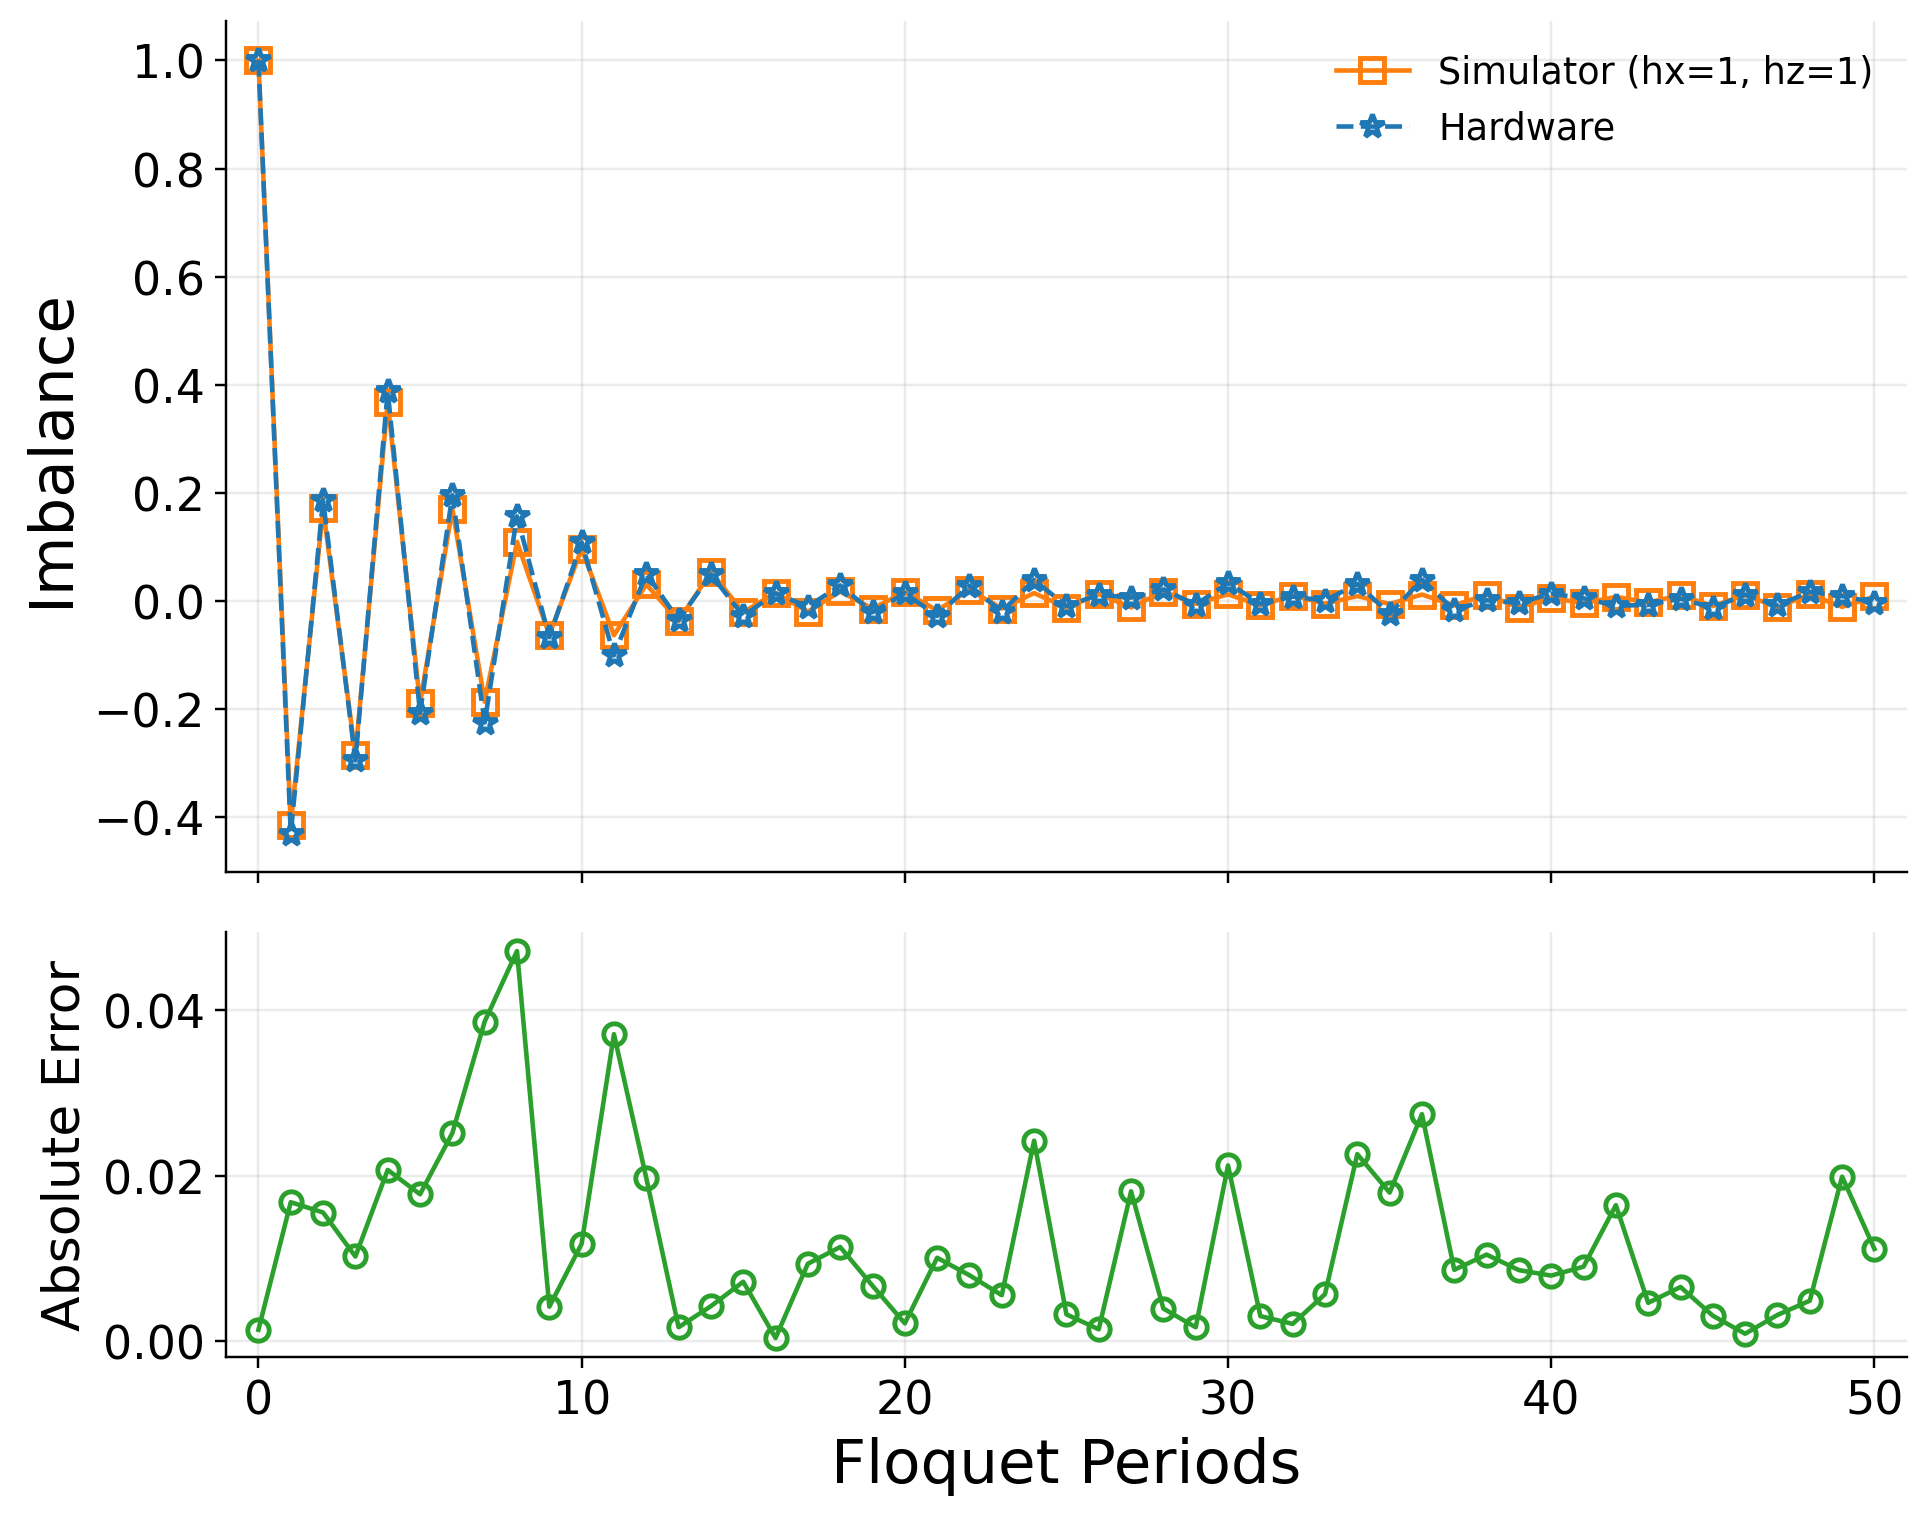

In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt

# c_sim = "#ff7f0e"  # orange
# c_hw  = "#1f77b4"  # blue
# c_err = "#2ca02c"  # green

# absolute_error = np.abs(np.array(imbalance_values) - np.array(imbalance_hardware))

# fig, (ax1, ax2) = plt.subplots(
#     2, 1, figsize=(9, 7), dpi=220,
#     sharex=True, gridspec_kw={"height_ratios": [2, 1]}
# )

# # Plot 1: Imbalance
# ax1.plot(floquet_periods, imbalance_values,
#          linestyle="-", linewidth=1.5,
#          marker="s", markersize=8, markerfacecolor="none",
#          markeredgewidth=1.6, color=c_sim,
#          label=f"Simulator (hx={hx}, hz={hz})")

# ax1.plot(floquet_periods, imbalance_hardware,
#          linestyle="--", linewidth=1.5,
#          marker="*", markersize=8, markerfacecolor="none",
#          markeredgewidth=1.6, color=c_hw,
#          label="Hardware")

# ax1.set_ylabel("Imbalance", fontsize=20)
# ax1.legend(frameon=False, fontsize=12, loc="upper right")

# # Plot 2: Absolute Error
# ax2.plot(floquet_periods, absolute_error,
#          linestyle="-", linewidth=1.5,
#          marker="o", markersize=7, markerfacecolor="none",
#          markeredgewidth=1.6, color=c_err)

# ax2.set_xlabel("Floquet Periods", fontsize=20)
# ax2.set_ylabel("Absolute Error", fontsize=17)

# # Common styling
# for ax in (ax1, ax2):
#     ax.tick_params(labelsize=15)
#     ax.grid(alpha=0.25, linewidth=0.8)
#     ax.spines["top"].set_visible(False)
#     ax.spines["right"].set_visible(False)
#     ax.margins(x=0.02)

# plt.tight_layout()
# plt.show()

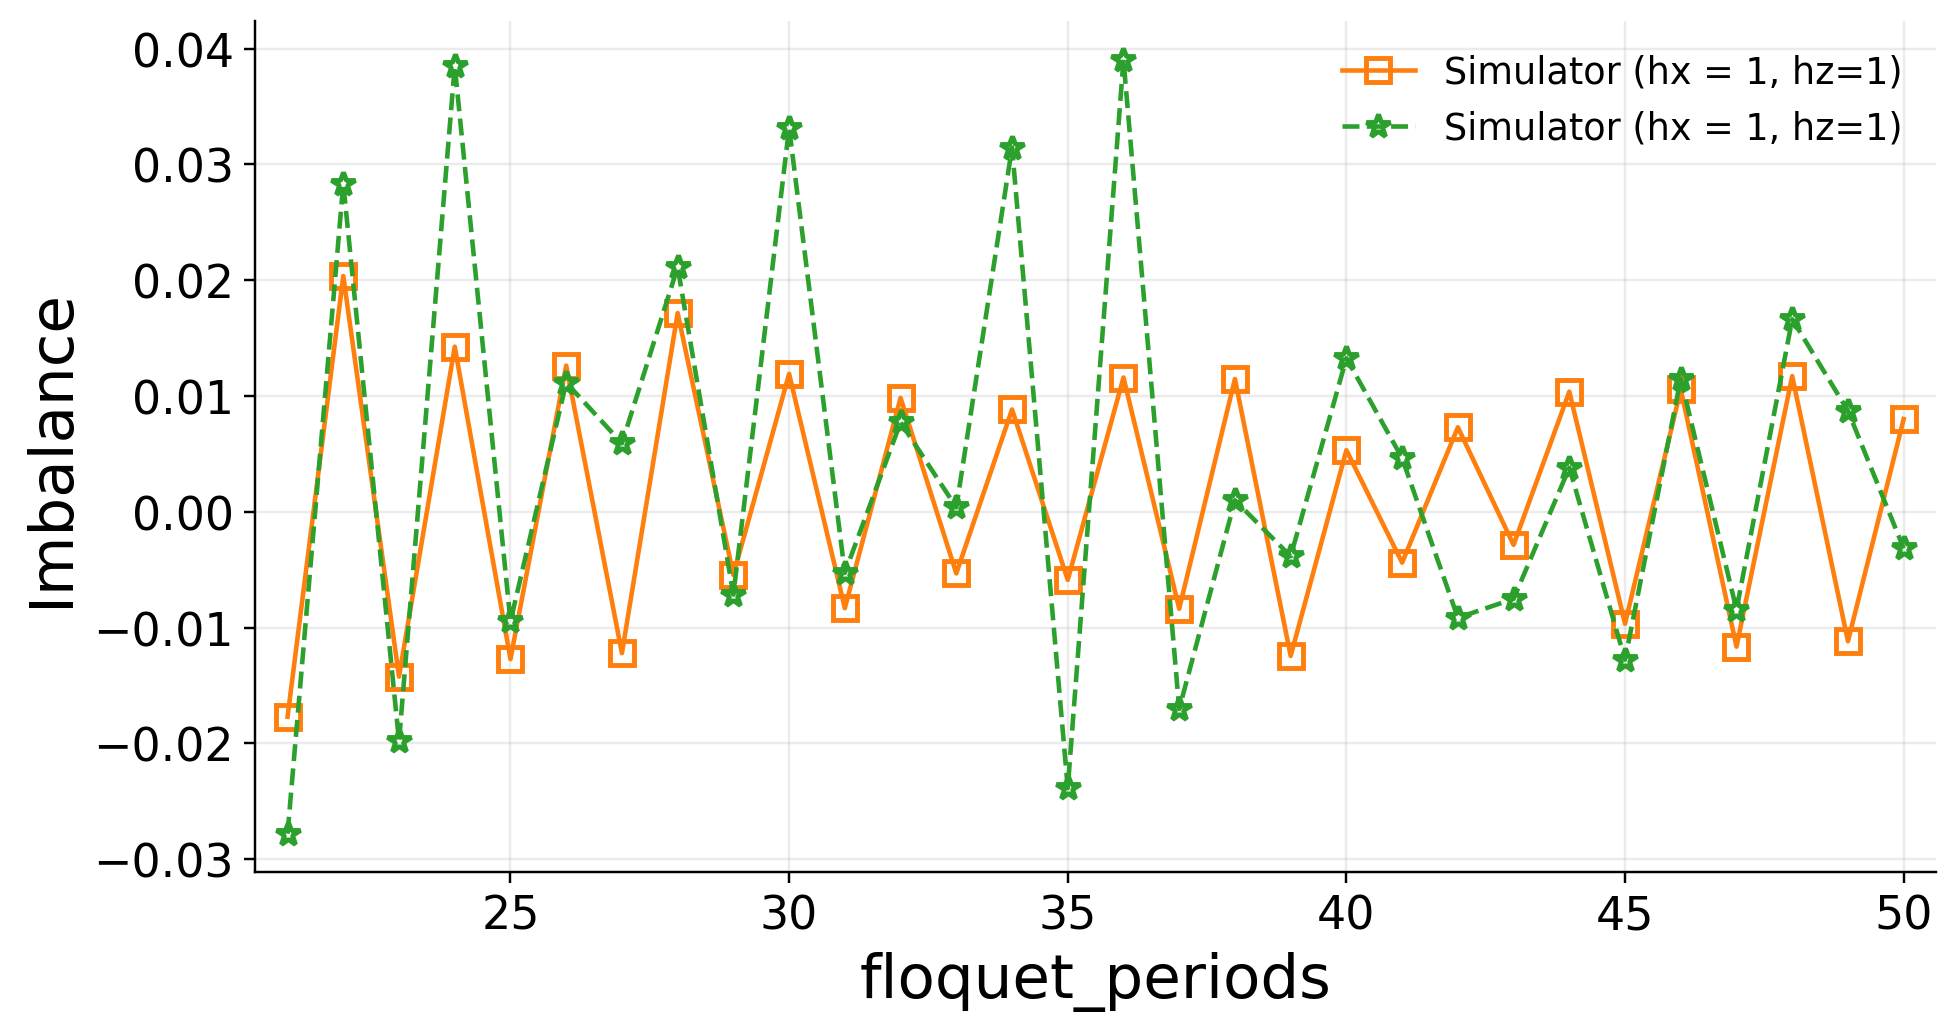

In [ ]:
# "------------------- Later time checking -------------------"


# c_sim = "#ff7f0e"  # orange
# c_hw  = "#1f77b4"  # blue
# c_ed  = "#2ca02c"  # green

# fig, ax = plt.subplots(figsize=(9, 4.8), dpi=220)

# # Simulator (Trotter S=6, h=6) — solid + hollow squares
# ax.plot(floquet_periods[21:], imbalance_values[21:],
#         linestyle="-", linewidth=1.5,
#         marker="s", markersize=8, markerfacecolor="none", markeredgewidth=1.6,
#         color=c_sim, label=f"Simulator (hx = {hx}, hz={hz})")

# ax.plot(floquet_periods[21:], imbalance_hardware[21:],
#         linestyle="--", linewidth=1.5,
#         marker="*", markersize=8, markerfacecolor="none", markeredgewidth=1.6,
#         color=c_ed, label=f"Simulator (hx = {hx}, hz={hz})")


# ax.set_xlabel("floquet_periods", fontsize=20)
# ax.set_ylabel("Imbalance", fontsize=20)
# ax.tick_params(labelsize=15)
# ax.grid(alpha=0.25, linewidth=0.8)
# ax.spines["top"].set_visible(False)
# ax.spines["right"].set_visible(False)
# ax.margins(x=0.02)
# ax.legend(frameon=False, fontsize=12, loc="upper right")

# plt.tight_layout()
# plt.show()
